# Project 01: Hệ đa agent cho bệnh tiểu đường

**Môn:** Phát triển Hệ thống Thông minh · **Sinh viên:** Nguyễn Thành Trung (B23DCCN861) · **Lớp:** D23CTPM01-B · **Nhóm lớp CT, nhóm 07**

Notebook này chạy lại từng thành phần của hệ đa agent trong thư mục `project01/` và giải thích kỹ từng đoạn mã. Nó đi cùng báo cáo
`project01_CT_07_TrungNT.861` và demo "Phòng khám AI" 3D (`python project01/server.py --open`, cổng 8200).

## Bài toán và ý tưởng

Bệnh tiểu đường tiến triển chậm nên nhiều người không biết mình có nguy cơ. Một công cụ hỗ trợ tốt cần làm bốn việc cùng lúc:
**dự đoán** nguy cơ từ chỉ số sức khỏe, **giải thích** bằng kiến thức y khoa có nguồn, **gợi ý hành động** mỗi ngày và **cảnh báo** khi nguy hiểm.
Mỗi việc cần một kỹ thuật khác nhau, nên hệ chia thành các agent chuyên trách và một bộ điều phối ghép kết quả lại.

| Agent | Kỹ thuật | Tệp mã | Phần của notebook |
|---|---|---|---|
| Bác sĩ dữ liệu | Deep Learning (MLP) huấn luyện trên BRFSS 2015 | `mas/dl_agent.py`, `train/train_dl.py` | Phần 1 |
| Thủ thư tri thức | Đồ thị tri thức + RAG (BM25 + Graph-RAG) | `mas/kb.py`, `train/build_kg.py` | Phần 2 |
| Huấn luyện viên | Reinforcement Learning (Q-learning) | `mas/rl.py`, `train/train_rl.py` | Phần 3 |
| Hộ lý an toàn | Luật cố định (rule-based) | `mas/rules.py` | Phần 4 |
| Bác sĩ trưởng + Thư ký báo cáo | Điều phối theo kịch bản, tự sinh hình và bảng | `mas/orchestrator.py`, `mas/report.py` | Phần 5 |

## Cách chạy và cách đọc

1. Chọn **Kernel → Restart Kernel and Run All** (khoảng 1–2 phút; mô hình đã huấn luyện được nạp từ `project01/artifacts/`).
2. Mỗi phần có thứ tự: **ô Markdown giải thích → ô mã → kết quả**. Hãy đọc phần giải thích trước khi nhìn mã.
3. Các ô "chạy thử thu nhỏ" huấn luyện lại một bản nhỏ để thấy vòng học thật sự chạy; kết quả chính thức dùng mô hình đã huấn luyện đầy đủ.

> **Lưu ý:** đây là sản phẩm học tập. Hệ thống không chẩn đoán và không thay thế bác sĩ; mô phỏng 24 giờ là mô hình đồ chơi.

## 0. Thiết lập môi trường

**Mục đích:** tìm thư mục gốc của dự án để `import project01...` hoạt động dù notebook được mở từ đâu, đặt kiểu biểu đồ, và liệt kê các tệp kết quả
đã huấn luyện (`artifacts/`).

**Giải thích từng dòng:**
- Vòng `while` đi ngược lên các thư mục cha cho tới khi gặp thư mục có `project01/mas`. Cách này tránh phải sửa đường dẫn khi chạy từ `notebooks/project01/`.
- `sys.path.insert(0, ROOT)` cho phép `from project01.mas ... import ...`.
- `show_source(obj)` in mã nguồn của một hàm hoặc lớp bằng `inspect.getsource`, để đọc đúng đoạn mã đang chạy thay vì chép tay.

In [1]:
import os, sys, json, inspect, random, time, base64, textwrap, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
while not (ROOT / "project01" / "mas").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
ART = ROOT / "project01" / "artifacts"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

def show_source(obj):
    print(textwrap.dedent(inspect.getsource(obj)))

print("Thư mục dự án:", ROOT)
for f in sorted(ART.iterdir()):
    print(f"{f.name:22s}{f.stat().st_size / 1024:9.1f} KB")

Thư mục dự án: E:\WINDOW\Project\intelligent-system-assignment-01
ask_eval.json               1.0 KB
diabetes_corpus_niddk183.jsonl     80.0 KB
dl_metrics.json            17.1 KB
dl_model.npz               54.8 KB
kg.json                    24.8 KB
kg_neo4j.cypher            14.6 KB
rag_metrics.json            4.1 KB
rl_metrics.json             5.0 KB
rl_qtable.json            101.2 KB
trust_metrics.json         26.4 KB


# Phần 1. Agent Deep Learning: dự đoán nguy cơ từ chỉ số sức khỏe

## 1.1. Dữ liệu BRFSS 2015

Dữ liệu là khảo sát sức khỏe BRFSS 2015 của CDC (Hoa Kỳ): **253.680 hồ sơ**, mỗi hồ sơ có **21 chỉ số** (huyết áp cao, mỡ máu, BMI, hút thuốc, vận động,
tự đánh giá sức khỏe, tuổi theo 13 nhóm, học vấn, thu nhập...) và một nhãn ba mức: `0` không tiểu đường, `1` tiền tiểu đường, `2` tiểu đường.

Điều cần chú ý là **mất cân bằng lớp**: nhóm tiền tiểu đường rất hiếm. Nếu huấn luyện thẳng, mô hình sẽ gần như không bao giờ đoán nhóm này. Ô dưới đây đọc
thống kê lớp từ tệp `dl_metrics.json` do `train_dl.py` ghi lại.

,Nhóm,Số hồ sơ,Tỉ lệ
0,Không tiểu đường,213703,84.24%
1,Tiền tiểu đường,4631,1.83%
2,Tiểu đường,35346,13.93%


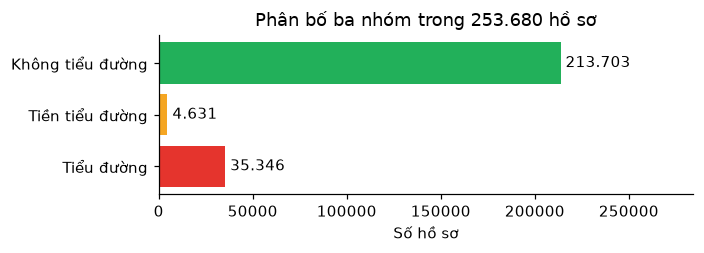

In [2]:
M = json.load(open(ART / "dl_metrics.json", encoding="utf-8"))
cc, total = M["class_counts"], M["rows"]
df_cls = pd.DataFrame({"Nhóm": ["Không tiểu đường", "Tiền tiểu đường", "Tiểu đường"], "Số hồ sơ": [cc["none"], cc["pre"], cc["diabetes"]]})
df_cls["Tỉ lệ"] = (df_cls["Số hồ sơ"] / total * 100).round(2).astype(str) + "%"
display(df_cls)

fig, ax = plt.subplots(figsize=(6.5, 2.4))
ax.barh(df_cls["Nhóm"][::-1], df_cls["Số hồ sơ"][::-1], color=["#e5342d", "#f5a623", "#22b05a"])
for y, v in enumerate(df_cls["Số hồ sơ"][::-1]):
    ax.text(v, y, f" {v:,}".replace(",", "."), va="center")
ax.set_xlim(0, total * 1.12); ax.set_xlabel("Số hồ sơ"); ax.set_title(f"Phân bố ba nhóm trong {total:,} hồ sơ".replace(",", "."))
plt.tight_layout(); plt.show()

## 1.2. Mô hình MLP và cách huấn luyện

Mô hình là mạng nơ-ron nhiều lớp (MLP) `21 → 128 → 64 → 32 → 3`: ba lớp ẩn dùng ReLU, có Dropout để giảm quá khớp, lớp cuối cho ba logit, qua softmax thành xác suất ba nhóm.

**Các quyết định thiết kế (đều nằm trong `train_dl.py`):**
- **Chuẩn hóa:** trừ trung bình, chia độ lệch chuẩn *tính trên tập huấn luyện*; tập kiểm tra dùng cùng thông số để không rò rỉ thông tin.
- **Hàm mất mát có trọng số lớp:** `CrossEntropyLoss(weight=...)` với trọng số `(n / (3·n_lớp))^0,75`. Số mũ 0,75 (thay vì 1) cân bằng một phần, tránh làm mô hình quá đoán lớp hiếm.
- **Chọn epoch** theo AUC trên tập *validation* riêng, không nhìn tập kiểm tra.
- **Hệ số điều chỉnh ngưỡng:** chỉ dùng để *gán nhãn* (không đổi xác suất hiển thị), chọn trên validation để cực đại macro-F1.
- **Suy luận bằng numpy:** sau huấn luyện, trọng số được xuất ra `dl_model.npz`; demo chạy chỉ cần numpy (không cần PyTorch). Hàm `numpy_forward` làm lại đúng phép tính của mạng
  và có phép kiểm tra `np.allclose` so với PyTorch.

Ô dưới in mã của hai hàm cốt lõi.

In [3]:
from project01.train import train_dl
show_source(train_dl.build_model)
show_source(train_dl.numpy_forward)

def build_model(n_in):
    return torch.nn.Sequential(
        torch.nn.Linear(n_in, 128), torch.nn.ReLU(), torch.nn.Dropout(0.15),
        torch.nn.Linear(128, 64), torch.nn.ReLU(), torch.nn.Dropout(0.1),
        torch.nn.Linear(64, 32), torch.nn.ReLU(),
        torch.nn.Linear(32, 3))

def numpy_forward(params, x):
    h = x
    for i, (w, b) in enumerate(params):
        h = h @ w + b
        if i < len(params) - 1:
            h = np.maximum(h, 0)
    h = h - h.max(axis=1, keepdims=True)
    e = np.exp(h)
    return e / e.sum(axis=1, keepdims=True)



### Chạy thử thu nhỏ vòng huấn luyện

Huấn luyện đầy đủ (14 epoch trên 253.680 hồ sơ) mất vài phút, nên ô này chạy một **bản thu nhỏ**: lấy ngẫu nhiên 40.000 hồ sơ, huấn luyện 5 epoch.
Mục đích là nhìn thấy vòng lặp thật sự chạy: mỗi epoch xáo trộn dữ liệu, chia mini-batch 1.024 mẫu, tính loss, lan truyền ngược (`loss.backward()`), cập nhật trọng số (`opt.step()`),
rồi đo AUC và macro-F1 trên validation. Kết quả chính thức của hệ thống dùng mô hình đầy đủ ở ô sau.

In [4]:
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, f1_score

df = pd.read_csv(ROOT / "data" / "diabetes" / "diabetes_012_health_indicators_BRFSS2015.csv").sample(40000, random_state=0)
y = df["Diabetes_012"].astype(int).values
X = df[train_dl.FEATURES].astype("float32").values
Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6          # thống kê chỉ tính trên tập huấn luyện
Xtr, Xva = (Xtr - mu) / sd, (Xva - mu) / sd

torch.manual_seed(0)
model = train_dl.build_model(len(train_dl.FEATURES))
w = torch.tensor((len(ytr) / (3 * np.bincount(ytr))) ** 0.75, dtype=torch.float32)   # trọng số lớp
loss_fn = torch.nn.CrossEntropyLoss(weight=w)
opt = torch.optim.Adam(model.parameters(), lr=2e-3, weight_decay=1e-5)
Xt, Yt, Xv = torch.tensor(Xtr), torch.tensor(ytr), torch.tensor(Xva)

rows = []
for epoch in range(1, 6):
    model.train()
    perm, tot = torch.randperm(len(Xt)), 0.0
    for i in range(0, len(Xt), 1024):
        idx = perm[i:i + 1024]
        opt.zero_grad()
        loss = loss_fn(model(Xt[idx]), Yt[idx])
        loss.backward()
        opt.step()
        tot += loss.item() * len(idx)
    model.eval()
    with torch.no_grad():
        pv = torch.softmax(model(Xv), 1).numpy()
    rows.append(dict(epoch=epoch, train_loss=round(tot / len(Xt), 4),
                     val_auc=round(roc_auc_score(yva, pv, multi_class="ovr"), 4),
                     val_macro_f1=round(f1_score(yva, pv.argmax(1), average="macro"), 4)))
display(pd.DataFrame(rows))

,epoch,train_loss,val_auc,val_macro_f1
0,1,0.9271,0.7804,0.4260
1,2,0.8586,0.7696,0.4402
2,3,0.8535,0.7846,0.4420
3,4,0.8478,0.7835,0.4515
4,5,0.8450,0.7817,0.4619


### Kết quả của mô hình đầy đủ

Ô dưới vẽ đường học (loss huấn luyện, AUC và macro-F1 trên validation; đường đứt là epoch tốt nhất) và so sánh MLP với **hồi quy logistic** cân bằng lớp làm đường cơ sở.

**Đọc kết quả trung thực:** MLP chỉ hơn hồi quy logistic một chút về AUC. Độ nhạy (recall) của nhóm *tiền tiểu đường* thấp, vì dữ liệu khảo sát không có xét nghiệm máu nên
ranh giới giữa "không" và "tiền" rất mờ. Vì vậy hệ thống dùng *chỉ số nguy cơ kết hợp* và luôn khuyên xét nghiệm xác nhận, thay vì coi nhãn dự đoán là kết luận.

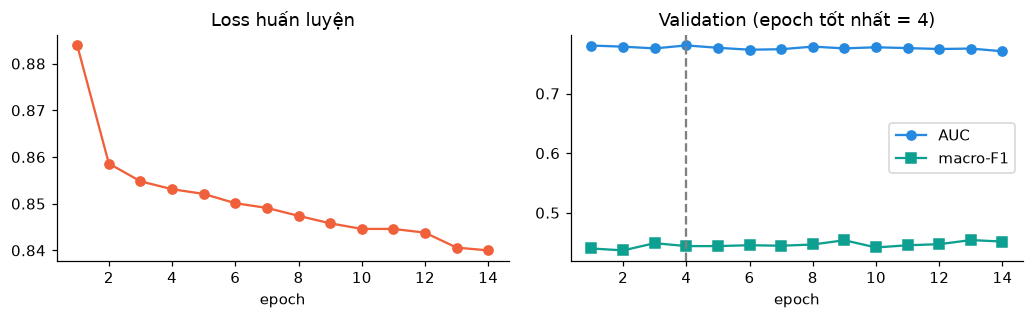

,Mô hình,Accuracy,Macro-F1,AUC (một-đấu-tất-cả)
0,Logistic Regression (cân bằng lớp),0.646,0.427,0.773
1,MLP 21-128-64-32-3 (có hệ số ngưỡng),0.752,0.461,0.782


Độ nhạy theo nhóm (không / tiền / tiểu đường): ['80%', '17%', '55%']


In [5]:
h = pd.DataFrame(M["history"])
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3))
ax[0].plot(h.epoch, h.train_loss, "o-", color="#f0603a"); ax[0].set_title("Loss huấn luyện"); ax[0].set_xlabel("epoch")
ax[1].plot(h.epoch, h.val_auc_ovr, "o-", color="#2589e0", label="AUC"); ax[1].plot(h.epoch, h.val_macro_f1, "s-", color="#0d9f8f", label="macro-F1")
ax[1].axvline(M["best_epoch"], ls="--", color="gray"); ax[1].legend(); ax[1].set_title(f"Validation (epoch tốt nhất = {M['best_epoch']})"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

b = M["baseline"]; rec = M["recall_per_class"]
display(pd.DataFrame([["Logistic Regression (cân bằng lớp)", b["accuracy"], b["macro_f1"], b["auc_ovr"]],
                      ["MLP 21-128-64-32-3 (có hệ số ngưỡng)", M["accuracy"], M["macro_f1"], M["auc_ovr"]]],
                     columns=["Mô hình", "Accuracy", "Macro-F1", "AUC (một-đấu-tất-cả)"]).round(3))
print("Độ nhạy theo nhóm (không / tiền / tiểu đường):", [f"{r:.0%}" for r in rec])

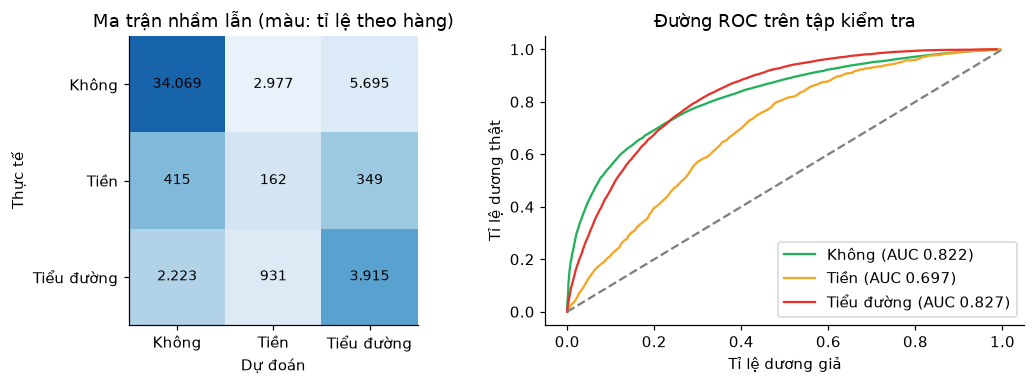

In [6]:
cm = np.array(M["confusion_matrix"]); names = ["Không", "Tiền", "Tiểu đường"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax[0].text(j, i, f"{cm[i, j]:,}".replace(",", "."), ha="center", va="center", color="black", fontsize=9)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(names); ax[0].set_yticks(range(3)); ax[0].set_yticklabels(names)
ax[0].set_xlabel("Dự đoán"); ax[0].set_ylabel("Thực tế"); ax[0].set_title("Ma trận nhầm lẫn (màu: tỉ lệ theo hàng)")
for key, label, col in [("none", "Không", "#22b05a"), ("pre", "Tiền", "#f5a623"), ("diabetes", "Tiểu đường", "#e5342d")]:
    r = M["roc"][key]; ax[1].plot(r["fpr"], r["tpr"], color=col, label=f"{label} (AUC {r['auc']:.3f})")
ax[1].plot([0, 1], [0, 1], "--", color="gray"); ax[1].legend(loc="lower right"); ax[1].set_title("Đường ROC trên tập kiểm tra")
ax[1].set_xlabel("Tỉ lệ dương giả"); ax[1].set_ylabel("Tỉ lệ dương thật")
plt.tight_layout(); plt.show()

## 1.3. Từ mô hình thành agent: `DLAgent.predict`

Một con số xác suất chưa đủ để tư vấn. `DLAgent.predict(profile)` làm bốn việc:
1. **Ánh xạ hồ sơ** thân thiện (tuổi, chiều cao, cân nặng, có hút thuốc không...) sang 21 chỉ số BRFSS (`data.normalize`, `data.to_vector`). Ví dụ BMI = cân nặng / chiều cao²; tuổi đổi thành nhóm 1–13.
2. **Chạy mạng** bằng numpy, ra xác suất ba nhóm; nhãn lấy theo xác suất nhân với hệ số ngưỡng.
3. **Chỉ số nguy cơ** `risk_index = P(tiểu đường) + 0,5·P(tiền tiểu đường)`: gộp hai nhóm có nguy cơ thành một số duy nhất để so sánh và đặt mức thấp / trung bình / cao.
4. **Giải thích:** *yếu tố tác động* (thay giá trị của từng yếu tố bằng trung bình dân số rồi xem chỉ số nguy cơ đổi bao nhiêu) và *what-if* (nếu đổi một yếu tố lối sống sang mức khỏe mạnh thì giảm bao nhiêu).

Lưu ý: hai phần giải thích mô tả những gì mô hình học từ dữ liệu quan sát, **không phải bằng chứng nhân quả**.

In [7]:
from project01.mas.dl_agent import DLAgent
show_source(DLAgent.predict)

def predict(self, profile: dict) -> dict:
    prof = normalize(profile)
    x = np.array([to_vector(prof)], dtype="float32")
    p = self._forward(x)[0]
    label = CLASSES[int((p * self.scale).argmax())]
    risk_index = float(self.index(p[None])[0])
    # tác động của từng yếu tố: thay bằng giá trị trung bình dân số
    base = float(self.index(self._forward(x))[0])
    drivers = []
    for j, name in enumerate(FEATURES):
        if name in ("CholCheck", "AnyHealthcare", "Education", "Income", "NoDocbcCost"):
            continue
        x2 = x.copy()
        x2[0, j] = self.pop_mean[j]
        delta = base - float(self.index(self._forward(x2))[0])
        drivers.append(dict(feature=name, vi=VI_FEATURE[name], value=float(x[0, j]), effect=round(delta, 4)))
    drivers.sort(key=lambda d: -abs(d["effect"]))
    what_if = []
    for name, healthy, text in MODIFIABLE:
        j = FEATURES.index(name)
        if (name == "BMI" and x[0, j] <= healthy + 0.5) or (name != "BMI" and x[0, j] == 

In [8]:
from project01.mas.data import PERSONAS
dl = DLAgent()
rows = []
for p in PERSONAS:
    r = dl.predict(p["profile"])
    rows.append({"Vai": p["name"], "Không": f"{r['risk']['none']:.1%}", "Tiền": f"{r['risk']['pre']:.1%}", "Tiểu đường": f"{r['risk']['diabetes']:.1%}",
                 "Nhãn": r["label"], "Chỉ số nguy cơ": round(r["risk_index"], 3), "BMI": round(r["bmi"], 1)})
display(pd.DataFrame(rows))

,Vai,Không,Tiền,Tiểu đường,Nhãn,Chỉ số nguy cơ,BMI
0,"Chị Lan, 34 tuổi",97.4%,1.6%,1.0%,none,0.018,20.6
1,"Anh Minh, 52 tuổi",22.5%,24.1%,53.4%,diabetes,0.654,30.4
2,"Bác Hùng, 67 tuổi",19.0%,20.8%,60.2%,diabetes,0.706,26.1
3,"Em An, 24 tuổi",96.4%,2.0%,1.6%,none,0.026,20.4
4,"Cô Hoa, 41 tuổi",95.2%,3.0%,1.8%,none,0.033,21.1


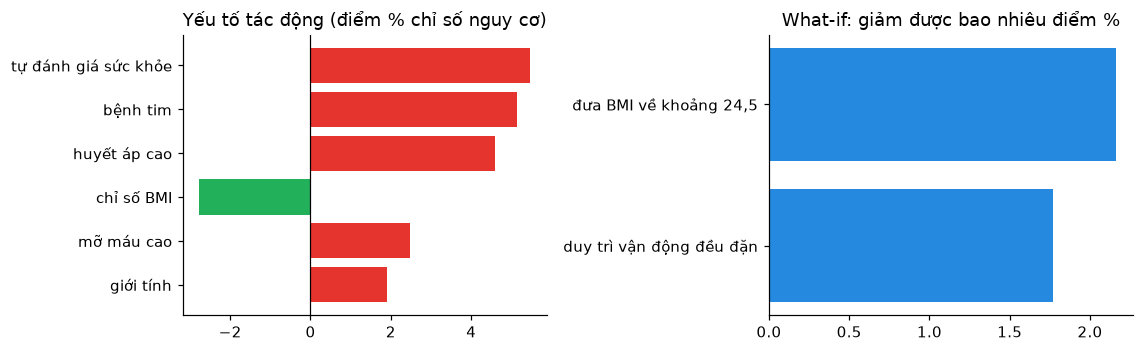

In [9]:
r = dl.predict(PERSONAS[2]["profile"])          # Bác Hùng, 67 tuổi
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.3))
d = pd.DataFrame(r["drivers"])[::-1]
ax[0].barh(d["vi"], d["effect"] * 100, color=np.where(d["effect"] > 0, "#e5342d", "#22b05a"))
ax[0].set_title("Yếu tố tác động (điểm % chỉ số nguy cơ)"); ax[0].axvline(0, color="black", lw=0.8)
if r["what_if"]:
    w = pd.DataFrame(r["what_if"])[::-1]
    ax[1].barh(w["action"], w["gain"] * 100, color="#2589e0"); ax[1].set_title("What-if: giảm được bao nhiêu điểm %")
plt.tight_layout(); plt.show()

# Phần 2. Agent tri thức: đồ thị tri thức và RAG

## 2.1. Đồ thị tri thức (Knowledge Graph)

Mô hình học sâu ở Phần 1 không biết "vì sao" nguy cơ tăng. Agent tri thức cung cấp phần đó bằng một **đồ thị tri thức**: nút là khái niệm y khoa (bệnh, triệu chứng, yếu tố nguy cơ,
xét nghiệm, điều trị, lối sống, biến chứng), cạnh là quan hệ có hướng (`raises_risk`, `symptom_of`, `diagnosed_by`...). Đồ thị do nhóm biên soạn (41 nút) dựa trên bốn trang của NIDDK,
mỗi nút gắn với các **đoạn trích** liên quan nhất (`passages`) để mọi câu trả lời đều có nguồn. Đồ thị được xuất ra Cypher (`kg_neo4j.cypher`) để nạp vào Neo4j.

Ô dưới đếm nút theo loại, cạnh theo quan hệ và in vài sự kiện dạng "A — quan hệ — B".

In [10]:
from project01.mas.kb import KnowledgeBase, REL_VI, BM25
kb = KnowledgeBase()
types = pd.Series([n["type"] for n in kb.nodes.values()]).value_counts().rename("Số nút").to_frame()
rels = pd.Series([REL_VI.get(e["rel"], e["rel"]) for e in kb.edges]).value_counts().rename("Số cạnh").to_frame()
display(types, rels)
print(f"Tổng: {len(kb.nodes)} nút, {len(kb.edges)} cạnh, {len(kb.bm25.docs) if hasattr(kb.bm25, 'docs') else '?'} đoạn trích")
for e in kb.edges[:6]:
    print("-", kb.nodes[e["source"]]["vi"], "—", REL_VI.get(e["rel"], e["rel"]), "—", kb.nodes[e["target"]]["vi"])

,Số nút
complication,8
risk_factor,8
condition,6
symptom,6
test,5
lifestyle,4
treatment,4


,Số cạnh
làm tăng nguy cơ,11
gây ra,10
được chẩn đoán bằng,8
được kiểm soát bằng,7
là triệu chứng của,6
có thể phòng ngừa bằng,4
là một dạng của,3
được theo dõi bằng,2
giúp cải thiện,2
là biến chứng của,1


Tổng: 41 nút, 54 cạnh, 168 đoạn trích
- Tiểu đường típ 1 — là một dạng của — Bệnh tiểu đường
- Tiểu đường típ 2 — là một dạng của — Bệnh tiểu đường
- Tiểu đường thai kỳ — là một dạng của — Bệnh tiểu đường
- Tiền tiểu đường — làm tăng nguy cơ — Tiểu đường típ 2
- Kháng insulin — gây ra — Tiểu đường típ 2
- Thừa cân, béo phì — gây ra — Kháng insulin


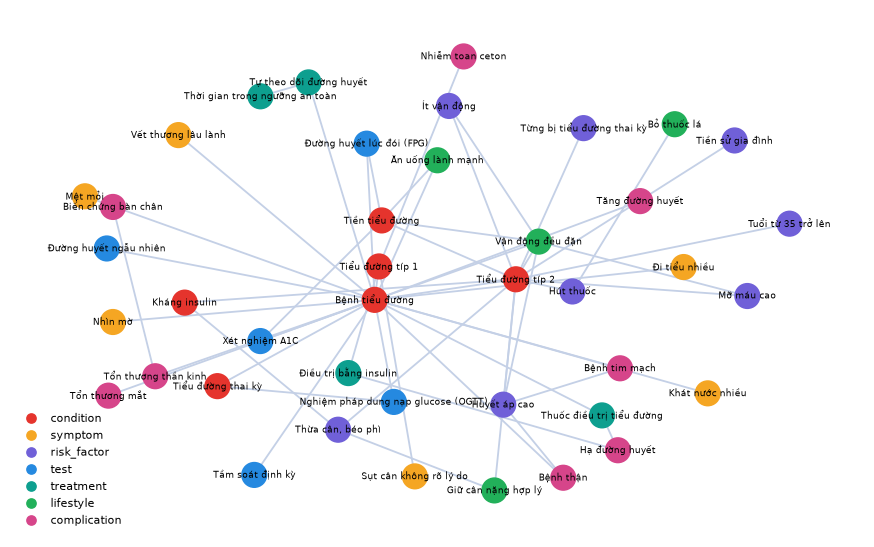

In [11]:
import networkx as nx
G = nx.DiGraph()
for nid, n in kb.nodes.items():
    G.add_node(nid, vi=n["vi"], type=n["type"])
for e in kb.edges:
    G.add_edge(e["source"], e["target"])
palette = {"condition": "#e5342d", "symptom": "#f5a623", "risk_factor": "#7060d8", "test": "#2589e0", "treatment": "#0d9f8f", "lifestyle": "#22b05a", "complication": "#d6458a"}
pos = nx.spring_layout(G.to_undirected(), seed=3, k=0.9)
fig, ax = plt.subplots(figsize=(10, 6.2)); ax.axis("off")
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#c4d0e6", arrows=False, width=1.2)
nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[palette.get(G.nodes[n]["type"], "#8896b0") for n in G], node_size=260)
nx.draw_networkx_labels(G, pos, labels={n: G.nodes[n]["vi"] for n in G}, ax=ax, font_size=6.2)
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=t) for t, c in palette.items()], loc="lower left", fontsize=7, frameon=False)
plt.show()

## 2.2. RAG: BM25 và Graph-RAG

**RAG (Retrieval-Augmented Generation)** trả lời bằng cách *tìm bằng chứng trước rồi mới nói*. Project này **chỉ trích nguyên văn** đoạn tài liệu kèm đường dẫn nguồn, không sinh văn bản tự do,
nên không có nguy cơ bịa nội dung y khoa.

- **BM25** là cách xếp hạng từ khóa kinh điển: điểm của một đoạn tăng khi chứa từ của câu hỏi (tần suất `tf`), giảm khi từ đó quá phổ biến (`idf`), có hiệu chỉnh theo độ dài đoạn (`k1`, `b`).
- **Graph-RAG** thêm đồ thị: (1) tìm các **nút khớp** câu hỏi (theo tên và từ đồng nghĩa), (2) mở rộng **một bước** sang nút láng giềng, (3) chạy BM25 như thường nhưng **cộng điểm**
  cho đoạn gắn với các nút đó (nút khớp +1,0; nút láng giềng +0,3). Bước (3) chính là lan truyền thông điệp cố định trên đồ thị.

Ô dưới in hàm `KnowledgeBase.search` để thấy đúng ba bước này.

In [12]:
show_source(KnowledgeBase.search)

def search(self, query: str, k: int = 3, graph: bool = True) -> dict:
    """Graph-RAG: tìm nút khớp truy vấn -> mở rộng 1 bước -> BM25 trên câu hỏi, cộng điểm cho đoạn gắn với các nút đó."""
    seeds = self.match_nodes(query) if graph else []
    nodes = self.expand(seeds)[:14] if seeds else []
    boost = {}
    for nid in nodes:  # đoạn gắn với nút khớp truy vấn được cộng 1,0; đoạn gắn với nút láng giềng được cộng 0,3
        weight = 1.0 if nid in seeds else 0.3
        for pid in self.nodes[nid].get("passages", []):
            boost[pid] = boost.get(pid, 0) + weight
    passages = self.bm25.search(query, k, boost if graph else None)
    facts = []
    for e in self.edges:
        if e["source"] in seeds or e["target"] in seeds:
            a, b = self.nodes[e["source"]]["vi"], self.nodes[e["target"]]["vi"]
            facts.append(f"{a} — {REL_VI.get(e['rel'], e['rel'])} — {b}")
    return dict(nodes=nodes, seeds=seeds, passages=passages, facts=facts[:8])



In [13]:
questions = ["What organ makes insulin?", "What are the symptoms of high blood sugar?", "How can type 2 diabetes be prevented?"]
rows = []
for q in questions:
    plain = kb.search(q, 3, graph=False)["passages"][0]
    g = kb.search(q, 3, graph=True)
    rows.append({"Câu hỏi": q, "Nút khớp": ", ".join(kb.nodes[s]["vi"] for s in g["seeds"][:3]) or "(không)",
                 "BM25: đoạn xếp 1": plain["id"], "Graph-RAG: đoạn xếp 1": g["passages"][0]["id"]})
display(pd.DataFrame(rows))
g = kb.search(questions[1], 3)
print("Trích dẫn xếp 1:", g["passages"][0]["quote"][:260], "...")
print("Nguồn:", g["passages"][0]["url"])
print("Sự kiện từ đồ thị:", g["facts"][:3])

,Câu hỏi,Nút khớp,BM25: đoạn xếp 1,Graph-RAG: đoạn xếp 1
0,What organ makes insulin?,"Điều trị bằng insulin, Kháng insulin",what-is-diabetes:14,what-is-diabetes:14
1,What are the symptoms of high blood sugar?,"Huyết áp cao, Mỡ máu cao, Tự theo dõi đường huyết",tests-diagnosis:50,managing-diabetes:66
2,How can type 2 diabetes be prevented?,"Tiểu đường típ 2, Bệnh tiểu đường, Tiểu đường ...",tests-diagnosis:30,tests-diagnosis:30


Trích dẫn xếp 1: When your blood glucose level is too high, it is called hyperglycemia. For most people with diabetes, the blood glucose level is too high when it is above 180 mg/dL. Talk with your health care team if you often have high blood glucose levels. Some people with  ...
Nguồn: https://www.niddk.nih.gov/health-information/diabetes/overview/managing-diabetes
Sự kiện từ đồ thị: ['Huyết áp cao — làm tăng nguy cơ — Tiểu đường típ 2', 'Mỡ máu cao — làm tăng nguy cơ — Tiểu đường típ 2', 'Bệnh tiểu đường — được theo dõi bằng — Tự theo dõi đường huyết']


**Đọc kết quả cụ thể:** trong ba câu mẫu, Graph-RAG chỉ đổi đoạn xếp 1 ở **câu thứ hai** (từ `tests-diagnosis:50` sang `managing-diabetes:66`, đoạn nói về hyperglycemia nên hợp ý hơn);
hai câu còn lại giữ nguyên thứ hạng của BM25. Cũng thấy một **hạn chế**: ở câu thứ hai, các nút khớp gồm "Huyết áp cao" vì từ khóa `high` trùng với tên nút, tức khớp nút bằng từ khóa còn thô.
Vì vậy đừng suy ra Graph-RAG luôn tốt hơn: lợi ích chỉ xuất hiện ở một phần câu hỏi và phụ thuộc chất lượng khớp nút.

,Phương pháp,hit@1,hit@3,MRR
0,BM25,0.375,0.562,0.484
1,Graph-RAG,0.438,0.625,0.521


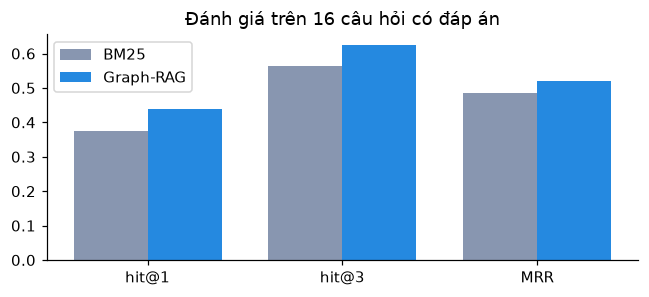

In [14]:
RAG = json.load(open(ART / "rag_metrics.json", encoding="utf-8"))
tab = pd.DataFrame([[k, RAG[k]["hit_at_1"], RAG[k]["hit_at_3"], RAG[k]["mrr"]] for k in ("BM25", "Graph-RAG")], columns=["Phương pháp", "hit@1", "hit@3", "MRR"])
display(tab.round(3))
fig, ax = plt.subplots(figsize=(6, 2.8)); x = np.arange(3)
for i, (k, c) in enumerate([("BM25", "#8896b0"), ("Graph-RAG", "#2589e0")]):
    ax.bar(x + i * 0.38 - 0.19, [RAG[k]["hit_at_1"], RAG[k]["hit_at_3"], RAG[k]["mrr"]], 0.38, label=k, color=c)
ax.set_xticks(x); ax.set_xticklabels(["hit@1", "hit@3", "MRR"]); ax.legend(); ax.set_title(f"Đánh giá trên {RAG['BM25']['questions']} câu hỏi có đáp án")
plt.tight_layout(); plt.show()

**Đọc kết quả thận trọng:** Graph-RAG nhỉnh hơn BM25 thuần, nhưng bộ đánh giá chỉ có 16 câu tiếng Anh và trọng số cộng điểm được chọn thử trên chính bộ này,
nên đây chỉ là xu hướng, không phải bằng chứng chắc chắn.

# Phần 3. Agent Reinforcement Learning: huấn luyện viên lối sống

## 3.1. Bài toán và môi trường mô phỏng

Không thể thử nghiệm lên người thật, nên nhóm xây một **bệnh nhân ảo** đơn giản. Mỗi bước là **một giờ**, một ngày có 24 bước (6 giờ sáng đến 5 giờ sáng hôm sau).

| Thành phần RL | Trong project |
|---|---|
| **Trạng thái** | giờ trong ngày, đường huyết, lượng tinh bột đang tiêu hóa, mức vận động gần đây, số giờ từ bữa ăn trước, độ nhạy insulin, có dùng thuốc không (rời rạc hóa thành 3.888 trạng thái) |
| **Hành động** | 7 hành động: nghỉ, ăn nhẹ có đường, bữa nhẹ, bữa chính, bữa nhiều tinh bột, đi bộ, tập thể dục (ban đêm chỉ được nghỉ hoặc ăn nhẹ có đường) |
| **Phần thưởng (reward)** | theo vùng đường huyết: +1 khi 70–140 mg/dL, giảm dần khi cao, âm mạnh khi dưới 55 hoặc quá cao; phạt khi quá lâu không ăn; thưởng nhỏ cho vận động |
| **Mục tiêu** | giữ đường huyết trong ngưỡng 70–180 mg/dL càng lâu càng tốt (time-in-range) |

Ô dưới in bảng hành động và bảng phần thưởng theo mức đường huyết.

In [15]:
from project01.mas import rl
display(pd.DataFrame(rl.ACTIONS)[["id", "label", "carbs", "act", "desc"]].rename(columns={"carbs": "tinh bột", "act": "vận động"}))
display(pd.DataFrame([{"Đường huyết (mg/dL)": g, "Vùng": rl.zone(g), "Phần thưởng": rl.zone_reward(g)} for g in (45, 65, 100, 170, 230, 320)]))

,id,label,tinh bột,vận động,desc
0,rest,Nghỉ ngơi,0,0.0,"Không ăn, không vận động"
1,sweet,Ăn nhẹ có đường,20,0.0,"Nước ngọt, kẹo hoặc chuối: đường lên nhanh, dù..."
2,light_meal,Bữa nhẹ,30,0.0,"Salad, sữa chua, trái cây: ít tinh bột"
3,normal_meal,Bữa chính,60,0.0,"Cơm, thịt cá và rau cân đối"
4,heavy_meal,Bữa nhiều tinh bột,100,0.0,"Cơm lớn, đồ chiên, tráng miệng ngọt"
5,walk,Đi bộ nhanh,0,1.0,Đi bộ khoảng 30 phút
6,workout,Tập thể dục,0,2.0,Chạy hoặc đạp xe khoảng 40 phút


,Đường huyết (mg/dL),Vùng,Phần thưởng
0,45,danger,-3.0
1,65,low,-1.0
2,100,ok,1.0
3,170,ok,0.3
4,230,high,-0.7
5,320,danger,-2.5


## 3.2. Một bước mô phỏng: `rl.step`

`step(state, action, rng)` tính đường huyết của giờ kế tiếp: bữa ăn làm tăng (nhanh hơn với đồ ngọt, mạnh hơn khi kháng insulin), vận động và thuốc làm giảm,
đường huyết tự kéo dần về mức nền, thêm một chút nhiễu ngẫu nhiên. Hàm trả về trạng thái mới, phần thưởng và thông tin (vùng, mức tăng, mức giảm).
Các tham số được đặt theo trực giác, **không hiệu chỉnh từ số liệu bệnh nhân thật**. Ô sau in mã và thử ba hành động từ cùng một trạng thái.

In [16]:
show_source(rl.step)

def step(state: dict, action: str, rng: random.Random) -> tuple[dict, float, dict]:
    """Một giờ mô phỏng. Trả về (trạng thái mới, phần thưởng, thông tin)."""
    p = state["patient"]
    s, base, med = p["insulin_sensitivity"], p["baseline_glucose"], p.get("medication", 0.0)
    act = ACTIONS[AID[action]]
    g, c, a = state["glucose"], state["carbs"], state["act"]
    c_total = c + act["carbs"]
    absorbed = c_total * (0.75 if act["fast"] else 0.45)
    c_after = c_total - absorbed
    rise = absorbed * 1.35 * (1.7 - s)
    a_total = a + act["act"]
    drop_act = a_total * 14 * (0.5 + 0.5 * s) * max(0.0, min(1.0, (g - 62) / 60))
    pull = (g - base) * 0.16 * s
    drop_med = med * max(0.0, min(1.0, (g - 55) / 60))
    g2 = g + rise - drop_act - pull - drop_med + rng.gauss(0, 3)
    g2 = max(35.0, min(420.0, g2))
    meal = action in MEALS
    since = 0 if meal else state["since_meal"] + 1
    reward = zone_reward(g2)
    night = is_night(state["hour"] + 1)
    if since >= 6 and n

In [17]:
patient = rl.patient_from_risk(0.4, 30.0, None, "Bệnh nhân mẫu")
print("Bệnh nhân:", patient)
state = rl.new_state(patient, random.Random(1))
print(f"Trạng thái đầu: {rl.clock(state['hour'])}h, đường huyết {state['glucose']} mg/dL\n")
rows = []
for action in ["normal_meal", "walk", "heavy_meal", "rest"]:
    new, reward, info = rl.step(state, action, random.Random(5))
    rows.append({"Hành động": action, "Đường huyết trước": state["glucose"], "Sau 1 giờ": new["glucose"], "Vùng": info["zone"], "Tăng": round(info["rise"], 1),
                 "Giảm": round(info["drop"], 1), "Reward": round(reward, 2)})
display(pd.DataFrame(rows))

Bệnh nhân: {'name': 'Bệnh nhân mẫu', 'insulin_sensitivity': 0.46, 'baseline_glucose': 130.0, 'medication': 10.0}
Trạng thái đầu: 6h, đường huyết 135.2 mg/dL



,Hành động,Đường huyết trước,Sau 1 giờ,Vùng,Tăng,Giảm,Reward
0,normal_meal,135.2,166.5,ok,45.2,10.0,0.30
1,walk,135.2,111.1,ok,0.0,20.2,1.25
2,heavy_meal,135.2,196.6,high,75.3,10.0,-0.70
3,rest,135.2,121.3,ok,0.0,10.0,1.00


## 3.3. Q-learning

Huấn luyện viên học bằng **Q-learning dạng bảng**: bảng `Q[trạng thái][hành động]` ước lượng tổng phần thưởng kỳ vọng nếu làm hành động đó rồi hành xử tốt về sau.
Sau mỗi bước, giá trị được cập nhật theo công thức

$$Q(s,a) \leftarrow Q(s,a) + \alpha \,\big[\, r + \gamma \max_{a'} Q(s',a') - Q(s,a) \,\big]$$

với `α` = 0,15 là tốc độ học, `γ` = 0,97 là hệ số chiết khấu. Khi huấn luyện dùng chiến lược **ε-greedy**: lúc đầu ε = 1 (thử hành động ngẫu nhiên để khám phá),
giảm dần tới 0,05 (chủ yếu khai thác điều đã học). Mỗi "episode" là một ngày của một bệnh nhân ngẫu nhiên (`random_patient`). Ô dưới in hàm `train`.

In [18]:
show_source(rl.train)

def train(episodes: int = 60000, seed: int = 11, alpha: float = 0.15, gamma: float = 0.97, log_every: int = 2000):
    rng = random.Random(seed)
    coach = QCoach()
    curve = []
    window = []
    for ep in range(episodes):
        eps = max(0.05, 1.0 - 0.95 * ep / (0.7 * episodes))
        st = new_state(random_patient(rng), rng)
        total = 0.0
        while not done(st):
            key = encode(st)
            a = coach.act(st, eps, rng)
            nst, r, _ = step(st, a, rng)
            fin = done(nst)
            target = r if fin else r + gamma * max(coach.values(encode(nst))[AID[x]] for x in allowed(nst["hour"]))
            v = coach.values(key)
            v[AID[a]] += alpha * (target - v[AID[a]])
            st, total = nst, total + r
        window.append(total)
        if (ep + 1) % log_every == 0:
            curve.append(dict(episode=ep + 1, mean_return=round(sum(window) / len(window), 3), epsilon=round(eps, 3)))
            window = []
    return coach, curve


### Chạy thử thu nhỏ

Huấn luyện đầy đủ dùng 60.000 ngày. Ô này chỉ chạy **4.000 ngày** (vài giây) để thấy phần thưởng trung bình tăng dần khi ε giảm; mô hình chính thức nằm trong `rl_qtable.json`.

Xong sau 2.1 giây; đã gặp 1314 trạng thái


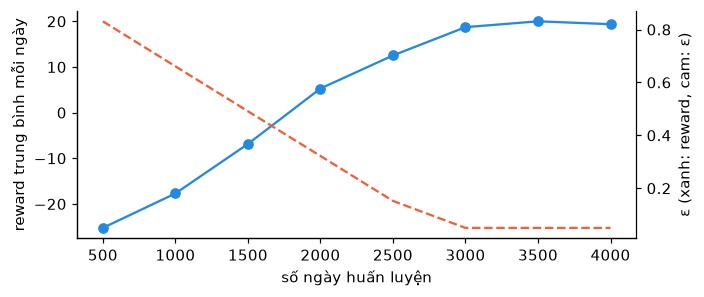

In [19]:
t0 = time.time()
mini, curve = rl.train(episodes=4000, seed=11, log_every=500)
print(f"Xong sau {time.time() - t0:.1f} giây; đã gặp {len(mini.q)} trạng thái")
c = pd.DataFrame(curve)
fig, ax = plt.subplots(figsize=(6.5, 2.8)); ax.plot(c.episode, c.mean_return, "o-", color="#2589e0"); ax2 = ax.twinx(); ax2.plot(c.episode, c.epsilon, "--", color="#f0603a")
ax.set_xlabel("số ngày huấn luyện"); ax.set_ylabel("reward trung bình mỗi ngày"); ax2.set_ylabel("ε (xanh: reward, cam: ε)"); ax2.spines["right"].set_visible(True)
plt.tight_layout(); plt.show()

## 3.4. So sánh ba huấn luyện viên

Ba chính sách được so sánh trên cùng bệnh nhân và cùng chuỗi nhiễu:
- **RL:** hành động có `Q` lớn nhất ở trạng thái hiện tại (`QCoach.act`).
- **Luật (`rule_coach`):** ăn đúng giờ, ăn nhẹ có đường khi dưới 75, đi bộ khi trên 160, tập mạnh khi trên 220.
- **Không có huấn luyện viên (`no_coach`):** ăn đúng giờ nhưng hay ăn vặt đồ ngọt, bữa tối nhiều tinh bột, ít vận động.

Ô sau chạy một ngày với mỗi chính sách cho bệnh nhân Anh Minh và vẽ đường đường huyết (vùng xanh là ngưỡng an toàn 70–180).

Bệnh nhân ảo suy ra từ hồ sơ: {'name': 'Anh Minh', 'insulin_sensitivity': 0.3, 'baseline_glucose': 136.7, 'medication': 10.0}


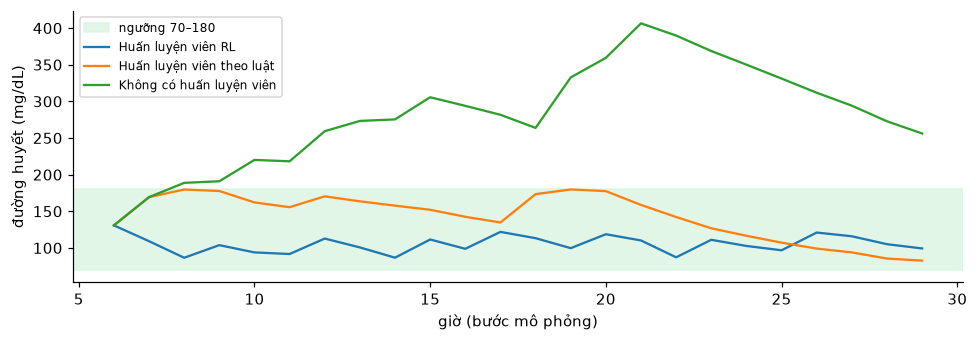

,Chính sách,Thời gian trong ngưỡng,Giờ quá thấp,Giờ quá cao,Tổng reward
0,Huấn luyện viên RL,100%,0,0,23.9
1,Huấn luyện viên theo luật,100%,0,0,13.4
2,Không có huấn luyện viên,8%,0,22,-47.7


In [20]:
coach = rl.QCoach.load()
minh = PERSONAS[1]["profile"]
r = dl.predict(minh)
pat = rl.patient_from_risk(r["risk_index"], r["bmi"], minh.get("fasting_glucose"), minh["name"])
print("Bệnh nhân ảo suy ra từ hồ sơ:", pat)
fig, ax = plt.subplots(figsize=(9, 3.2)); ax.axhspan(70, 180, color="#d7f3df", alpha=0.7, label="ngưỡng 70–180")
rows = []
for pid, (name, pol) in rl.policies(coach).items():
    day = rl.run_day(pol, pat, seed=3)
    ax.plot([x["hour"] for x in day["rows"]], [x["glucose"] for x in day["rows"]], label=name)
    rows.append({"Chính sách": name, "Thời gian trong ngưỡng": f"{day['tir']:.0%}", "Giờ quá thấp": day["hypo"], "Giờ quá cao": day["hyper"], "Tổng reward": round(day["total"], 1)})
ax.set_xlabel("giờ (bước mô phỏng)"); ax.set_ylabel("đường huyết (mg/dL)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show(); display(pd.DataFrame(rows))

In [21]:
RLM = json.load(open(ART / "rl_metrics.json", encoding="utf-8"))
rows = []
for gname, grp in RLM["evaluation"].items():
    for pid in ("rl", "rule", "none"):
        x = grp[pid]; rows.append({"Nhóm bệnh nhân": gname, "Chính sách": x["name"], "Trong ngưỡng": f"{x['time_in_range']:.0%}", "Đường huyết TB": x["mean_glucose"], "Giờ cao": x["hyper_hours"], "Điểm/ngày": x["mean_reward"]})
display(pd.DataFrame(rows))

,Nhóm bệnh nhân,Chính sách,Trong ngưỡng,Đường huyết TB,Giờ cao,Điểm/ngày
0,"nhạy insulin tốt (s ≥ 0,85)",Huấn luyện viên RL,100%,110.4,0.00,23.00
1,"nhạy insulin tốt (s ≥ 0,85)",Huấn luyện viên theo luật,100%,133.4,0.00,17.25
2,"nhạy insulin tốt (s ≥ 0,85)",Không có huấn luyện viên,72%,162.0,6.61,3.46
3,"trung bình (0,55 ≤ s < 0,85)",Huấn luyện viên RL,100%,108.4,0.00,23.39
4,"trung bình (0,55 ≤ s < 0,85)",Huấn luyện viên theo luật,94%,151.9,1.33,10.13
5,"trung bình (0,55 ≤ s < 0,85)",Không có huấn luyện viên,16%,231.2,20.09,-28.61
6,"kháng insulin (s < 0,55)",Huấn luyện viên RL,100%,113.4,0.00,23.23
7,"kháng insulin (s < 0,55)",Huấn luyện viên theo luật,75%,159.6,6.07,4.79
8,"kháng insulin (s < 0,55)",Không có huấn luyện viên,8%,282.3,22.05,-43.74


**Đọc kết quả trung thực:** huấn luyện viên RL giữ đường huyết trong ngưỡng gần như toàn bộ thời gian, luật làm tốt với bệnh nhân nhạy insulin nhưng kém dần khi kháng insulin tăng,
còn trường hợp không có huấn luyện viên rất thấp ở nhóm kháng insulin. Con số gần 100% của RL phản ánh việc môi trường mô phỏng **khá đơn giản và có thể học thuộc**,
không có nghĩa agent sẽ đạt kết quả như vậy với người thật.

# Phần 4. Agent luật an toàn

Trong y tế, hành vi an toàn cần **dự đoán được và giải thích được**, nên phần cảnh báo dùng luật cố định do con người viết (không học). Hộ lý an toàn có 10 luật (R1–R10), mỗi luật có mức
(`danger` khẩn, `warn` lưu ý, `info` nhắc) và căn cứ (ADA/NIDDK). Ví dụ R1: đường huyết ≥ 250 mg/dL; R5: đường huyết < 70 mg/dL; R7: BMI ≥ 30.
Agent chạy **độc lập với mô hình học**: nếu có luật mức khẩn thì bác sĩ trưởng luôn nâng mức nguy cơ lên *cao* dù mô hình nói gì.

In [22]:
from project01.mas import rules
show_source(rules.evaluate)

def evaluate(profile: dict, risk_index: float | None = None, p_diabetes: float | None = None) -> list[dict]:
    """Trả về danh sách luật đã kích hoạt: id, mức (info|warn|danger), nội dung, căn cứ."""
    p = normalize(profile)
    g = p["fasting_glucose"]
    sym = p["symptoms"]
    out = []

    def add(rid, level, text, basis):
        out.append(dict(id=rid, level=level, text=text, basis=basis))

    classic = [s for s in ("thirst", "frequent_urination", "weight_loss", "blurred_vision") if s in sym]
    if g is not None and g >= 250:
        add("R1", "danger", f"Đường huyết {g:.0f} mg/dL rất cao. Hãy đi khám hoặc đến cơ sở y tế trong ngày, đặc biệt nếu khát nhiều, tiểu nhiều, buồn nôn hoặc thở nhanh.",
            "Ngưỡng cảnh báo của demo (≥ 250 mg/dL); đường huyết ngẫu nhiên ≥ 200 mg/dL kèm triệu chứng gợi ý tiểu đường (ADA/NIDDK)")
    elif g is not None and g >= 200 and classic:
        add("R2", "danger", f"Đường huyết {g:.0f} mg/dL kèm triệu chứng ({', '.join(SYM[s].lower() 

In [23]:
for p in (PERSONAS[0], PERSONAS[2]):
    r = dl.predict(p["profile"])
    out = rules.evaluate(dict(p["profile"]), r["risk_index"], r["risk"]["diabetes"])
    print(f"=== {p['name']}: {len(out)} luật được kích hoạt, mức cao nhất = {rules.top_level(out) if out else '(không)'}")
    if out:
        display(pd.DataFrame(out)[["id", "level", "text", "basis"]])

=== Chị Lan, 34 tuổi: 0 luật được kích hoạt, mức cao nhất = (không)
=== Bác Hùng, 67 tuổi: 2 luật được kích hoạt, mức cao nhất = danger


,id,level,text,basis
0,R1,danger,Đường huyết 262 mg/dL rất cao. Hãy đi khám hoặ...,Ngưỡng cảnh báo của demo (≥ 250 mg/dL); đường ...
1,R8,warn,"Huyết áp cao, mỡ máu cao và bệnh tim/đột quỵ c...",NIDDK: tiểu đường làm tăng nguy cơ bệnh tim và...


# Phần 5. Bác sĩ trưởng: điều phối và báo cáo tự sinh

`Clinic.consult(profile)` (trong `mas/orchestrator.py`) chạy các agent theo thứ tự cố định: bác sĩ dữ liệu → thủ thư tri thức → hộ lý an toàn → bác sĩ phản biện → huấn luyện viên → thư ký báo cáo.
Các agent **không gọi trực tiếp nhau**; bác sĩ trưởng mời lần lượt từng agent và nhận kết quả có cấu trúc, nên mỗi bước đều truy vết được.

Kết quả trả về là một **danh sách sự kiện** theo giao thức thống nhất, giao diện 3D diễn hoạt từng sự kiện:

| Loại sự kiện | Ý nghĩa |
|---|---|
| `speak` | một agent phát biểu |
| `handoff` | bác sĩ trưởng chuyển lượt cho agent khác |
| `tool` | agent chạy công cụ (mô hình, vẽ hình) |
| `cite` | thủ thư tri thức trích dẫn tài liệu |
| `alert` | hộ lý an toàn cảnh báo |
| `final` | kết luận cuối |

Mức nguy cơ do `Clinic.level` quyết định: chỉ số nguy cơ dưới 10% là *thấp*, dưới 25% là *trung bình*, từ 25% là *cao*; cảnh báo khẩn luôn nâng lên *cao*, cảnh báo lưu ý nâng *thấp* thành *trung bình*.

In [24]:
from project01.mas.orchestrator import Clinic
clinic = Clinic()
show_source(Clinic.level)

def level(self, dl: dict, rule_list: list[dict]) -> str:
    r = dl["risk_index"]
    lv = "thấp" if r < 0.10 else "trung bình" if r < 0.25 else "cao"
    top = rules.top_level(rule_list)
    if top == "danger":
        return "cao"
    if top == "warn" and lv == "thấp":
        return "trung bình"
    return lv



In [25]:
t0 = time.time()
result = clinic.consult(PERSONAS[2]["profile"])         # Bác Hùng
print(f"Một lượt hội chẩn mất {time.time() - t0:.1f} giây, {len(result['events'])} sự kiện\n")
ev = pd.DataFrame([{"i": e["i"], "agent": e["agent"], "loại": e["type"], "nội dung": e["text"][:110] + ("…" if len(e["text"]) > 110 else "")} for e in result["events"]])
display(ev)

Một lượt hội chẩn mất 0.4 giây, 15 sự kiện



,i,agent,loại,nội dung
0,0,doctor,speak,"Chào Bác Hùng! Hồ sơ của bạn: 67 tuổi, nam, BM..."
1,1,doctor,handoff,Mời Bác sĩ dữ liệu ước lượng nguy cơ trước.
2,2,predictor,tool,Mô hình học từ 253.680 hồ sơ ước lượng: không ...
3,3,doctor,handoff,Cảm ơn! Thủ thư tri thức hãy tra cứu giúp tài ...
4,4,knowledge,cite,Mình đối chiếu 17 khái niệm trong đồ thị tri t...
5,5,doctor,handoff,Hộ lý an toàn hãy kiểm tra các dấu hiệu nguy h...
6,6,guardian,alert,[R1] Đường huyết 262 mg/dL rất cao. Hãy đi khá...
7,7,guardian,alert,"[R8] Huyết áp cao, mỡ máu cao và bệnh tim/đột ..."
8,8,doctor,handoff,"Bác sĩ phản biện, nhờ bạn kiểm tra chéo kết lu..."
9,9,critic,verdict,Mình đã kiểm tra chéo kết luận của Bác sĩ dữ l...


In [26]:
s = result["summary"]
print("Mức nguy cơ:", s["level"], "| chỉ số nguy cơ:", s["risk_index"], "| nhãn mô hình:", s["label"])
print("Kết luận:", s["headline"])
print("\nCờ đỏ:"); [print("  -", f["id"], f["text"]) for f in s["red_flags"]]
print("\nLời khuyên:"); [print("  -", a) for a in s["advice"]]
print("\nTrích dẫn:"); [print("  -", c["id"], c["url"]) for c in s["citations"]]

Mức nguy cơ: cao | chỉ số nguy cơ: 0.7062 | nhãn mô hình: diabetes
Kết luận: Nguy cơ cao: nên đi xét nghiệm xác nhận sớm.

Cờ đỏ:
  - R1 Đường huyết 262 mg/dL rất cao. Hãy đi khám hoặc đến cơ sở y tế trong ngày, đặc biệt nếu khát nhiều, tiểu nhiều, buồn nôn hoặc thở nhanh.
  - R8 Huyết áp cao, mỡ máu cao và bệnh tim/đột quỵ cùng tồn tại: nguy cơ biến chứng tim mạch cao, cần theo dõi cùng bác sĩ.

Lời khuyên:
  - Đường huyết 262 mg/dL rất cao. Hãy đi khám hoặc đến cơ sở y tế trong ngày, đặc biệt nếu khát nhiều, tiểu nhiều, buồn nôn hoặc thở nhanh.
  - Huyết áp cao, mỡ máu cao và bệnh tim/đột quỵ cùng tồn tại: nguy cơ biến chứng tim mạch cao, cần theo dõi cùng bác sĩ.
  - Đưa BMI về khoảng 24,5: mô hình cho thấy có thể giảm khoảng 2 điểm phần trăm chỉ số nguy cơ.
  - Duy trì vận động đều đặn: mô hình cho thấy có thể giảm khoảng 2 điểm phần trăm chỉ số nguy cơ.
  - Theo huấn luyện viên RL: 7h 🥗 bữa nhẹ, 8h 🚶 đi bộ nhanh, 9h 🏃 tập thể dục, 11h 🥗 bữa nhẹ, 12h 🏃 tập thể dục.
  - Nên làm xét 

[None, None, None]

## Báo cáo tự sinh: hình và bảng

Thư ký báo cáo (`mas/report.py`) vẽ bằng matplotlib ba hình (xác suất ba nhóm so với tỉ lệ trong dữ liệu, yếu tố tác động cùng what-if, một ngày mô phỏng của ba huấn luyện viên)
rồi mã hóa PNG sang base64 để gửi qua API; bảng gồm hồ sơ so với dân số, nguy cơ, what-if, cảnh báo, kế hoạch ngày, so sánh huấn luyện viên và nguồn trích dẫn.
Ô dưới giải mã và hiển thị chúng ngay trong notebook.

Nguy cơ theo mô hình - Ba cột là xác suất mô hình gán cho bạn; vạch đứt là tỉ lệ thực trong dữ liệu BRFSS 2015.


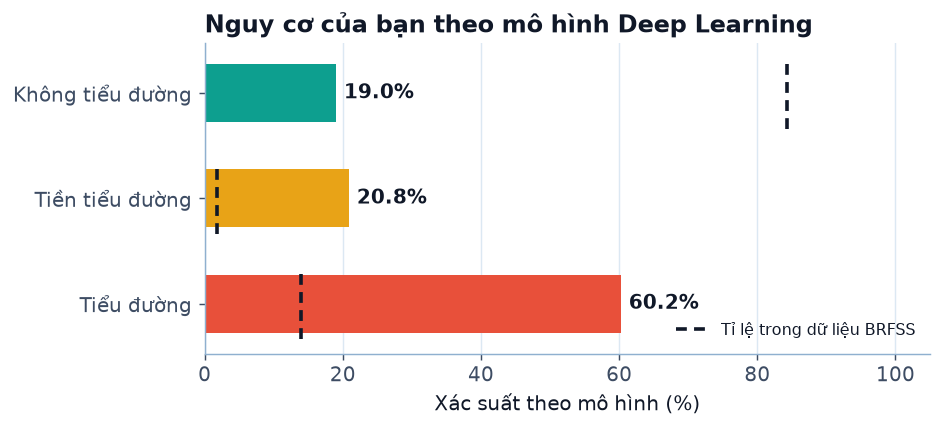

Yếu tố tác động và what-if - Trái: thay từng yếu tố bằng giá trị trung bình dân số để xem nó đẩy nguy cơ lên hay xuống. Phải: nguy cơ giảm được nếu cải thiện lối sống.


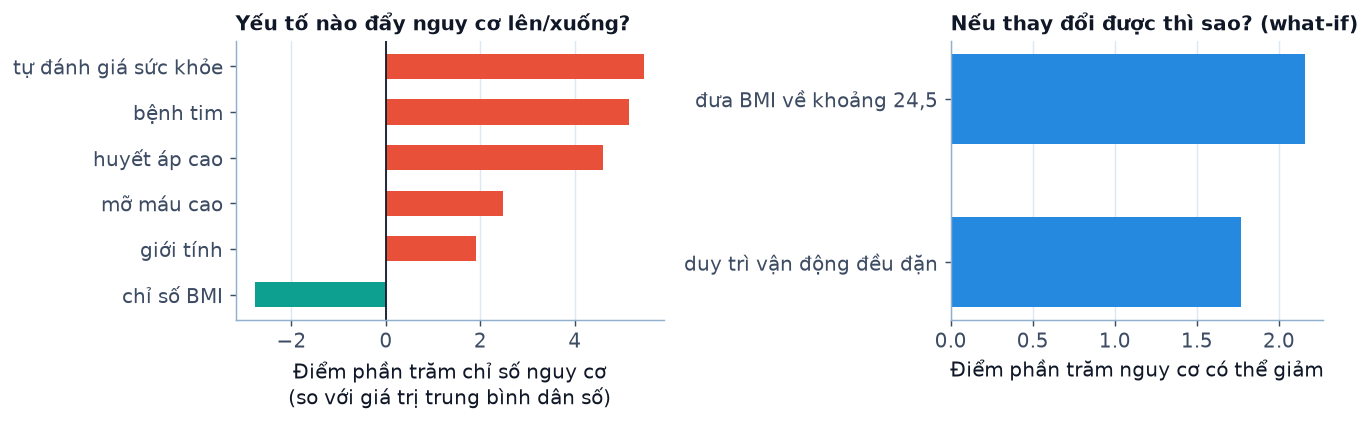

Một ngày mô phỏng - Đường huyết trung bình theo giờ khi có huấn luyện viên RL, huấn luyện viên theo luật và khi không có ai (mô phỏng đồ chơi, không phải y khoa thật).


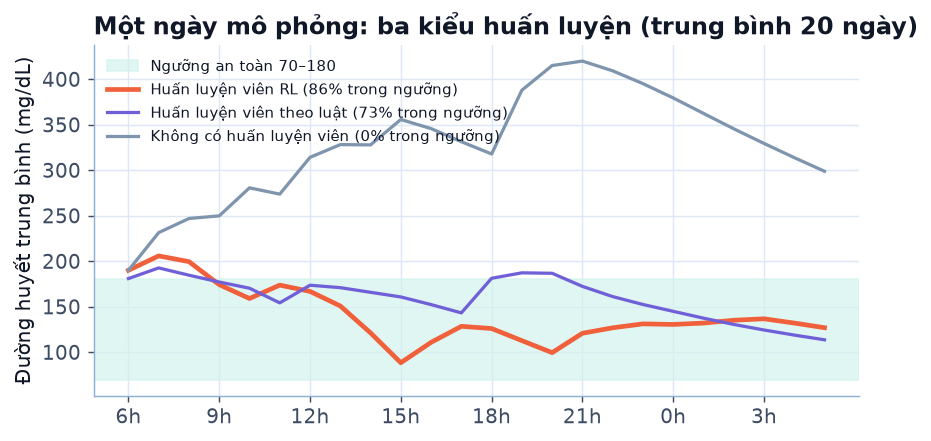


Hồ sơ của bạn so với dân số trong dữ liệu


,Chỉ số,Của bạn,Trung bình BRFSS
0,Tuổi,67,—
1,Giới tính,Nam,44% nam
2,BMI,26.1,28.4
3,Huyết áp cao,Có,43% có
4,Mỡ máu cao,Có,42% có
5,Hút thuốc,Không,44% có
6,Có vận động,Không,76% có
7,Tự đánh giá sức khỏe (1 tốt – 5 kém),4,2.5
8,Đường huyết đói,262 mg/dL,—
9,Triệu chứng,"Khát nước nhiều, Đi tiểu nhiều, Sụt cân không ...",—



Nguy cơ theo mô hình


,Nhóm,Xác suất,Tỉ lệ trong BRFSS
0,Không tiểu đường,19.0%,84.2%
1,Tiền tiểu đường,20.8%,1.8%
2,Tiểu đường,60.2%,13.9%



Thay đổi nào giúp giảm nguy cơ nhiều nhất


,Hành động,Giảm chỉ số nguy cơ
0,"Đưa bmi về khoảng 24,5",2.2 điểm %
1,Duy trì vận động đều đặn,1.8 điểm %



Tổng cộng: 3 hình và 7 bảng


In [27]:
rep = result["report"]
for f in rep["figures"]:
    print(f["title"], "-", f["caption"])
    display(Image(data=base64.b64decode(f["png_base64"]), width=640))
for t in rep["tables"][:3]:
    print("\n" + t["title"]); display(pd.DataFrame(t["rows"], columns=t["columns"]))
print("\nTổng cộng:", len(rep["figures"]), "hình và", len(rep["tables"]), "bảng")

# Phần 5b. Bác sĩ phản biện: kiểm tra chéo và tranh luận

**Vấn đề:** mô hình MLP chỉ nhìn 21 chỉ số khảo sát và **không có đường huyết trong đầu vào**. Một người trông khỏe mạnh nhưng xét nghiệm đường huyết đói 190 mg/dL vẫn có thể được mô hình báo nguy cơ thấp.
Nếu chỉ hỏi lại chính mô hình thì nó sẽ tự đồng ý với mình, nên agent thứ bảy, **Bác sĩ phản biện** (`mas/critic.py`), dùng ba nguồn bằng chứng *chạy được và độc lập với mô hình*:

1. **Luật an toàn** (`rules.py`) cùng ngưỡng ADA mà luật dựa vào (đường huyết đói ≥ 126 mg/dL).
2. **Số liệu thật của hồ sơ** (đường huyết, triệu chứng) và **phép thử độ nhạy** chạy lại chính mô hình khi cân nặng lệch ±5 kg.
3. **Đoạn trích có nguồn** từ kho tri thức 492 đoạn NIDDK/CDC/MedlinePlus (`data/chapter04/diabetes_corpus.jsonl`).

Bốn phép thử: C1 đường huyết so với mô hình, C2 triệu chứng so với mô hình, C3 độ chắc chắn (hai nhóm đứng đầu cách nhau bao nhiêu), C4 độ nhạy với sai số đo.
Khi có **mâu thuẫn thật** các agent tranh luận **tối đa 2 vòng**: vòng 1 bác sĩ phản biện nêu bằng chứng và bác sĩ dữ liệu bảo vệ; vòng 2 hộ lý an toàn nêu luật, thủ thư tri thức đọc nguyên văn tài liệu, bác sĩ phản biện kết luận.
Nguyên tắc kết luận: khi mô hình và **số đo trực tiếp** mâu thuẫn thì ưu tiên số đo và nâng mức nguy cơ (vẫn đề nghị xét nghiệm xác nhận). Trên giao diện 3D, các lượt tranh luận hiện thành bong bóng hội thoại và được đọc bằng giọng nói.

In [28]:
from project01.mas import critic
show_source(critic.review)

def review(clinic, prof: dict, dl: dict, rule_list: list[dict], base_level: str) -> dict:
    prof = normalize(prof)
    g = prof["fasting_glucose"]
    sym = [s for s in ("thirst", "frequent_urination", "weight_loss", "blurred_vision") if s in prof["symptoms"]]
    ri, risk = dl["risk_index"], dl["risk"]
    mlp_level = _lv(ri)
    ordered = sorted(risk.items(), key=lambda kv: -kv[1])
    margin = ordered[0][1] - ordered[1][1]
    stab = _stability(clinic.dl, prof)
    recall_pre = clinic.dl.metrics["recall_per_class"][1]
    checks, conflicts = [], []

    def add(cid, title, status, evidence, source, **kw):
        c = dict(id=cid, title=title, status=status, evidence=evidence, source=source, **kw)
        checks.append(c)
        if status in ("conflict", "soft"):
            conflicts.append(c)

    # --- C1: đường huyết đo trực tiếp so với nguy cơ của mô hình
    if g is None:
        add("C1", "Đường huyết so với mô hình", "na", "Chưa có đường huyết đói để đối chiếu; mô hình cũn

In [29]:
hoa = next(p for p in PERSONAS if p["id"] == "hoa")           # cô Hoa: đường huyết đói 190, hồ sơ lối sống lành mạnh
res_hoa = clinic.consult(hoa["profile"])
cr = res_hoa["summary"]["critique"]
print(f"Mô hình nói: {cr['mlp_level']} | sau luật: {cr['base_level']} | sau phản biện: {cr['final_level']} | kết cục: {cr['outcome']} | số vòng: {cr['rounds']}\n")
display(pd.DataFrame([{"phép thử": c["id"], "tên": c["title"], "kết quả": c["status"], "bằng chứng": c["evidence"], "nguồn": c["source"]} for c in cr["checks"]]))
for e in res_hoa["events"]:
    if e.get("round") is not None:
        print(f"[vòng {e['round']}] {e['agent']:<10} ({e['type']}): {e['text']}\n")

Mô hình nói: thấp | sau luật: trung bình | sau phản biện: cao | kết cục: escalated | số vòng: 2



,phép thử,tên,kết quả,bằng chứng,nguồn
0,C1,Đường huyết so với mô hình,conflict,Đường huyết đói 190 mg/dL ≥ 126 (ngưỡng tiểu đ...,Luật R3 + ADA
1,C2,Triệu chứng so với mô hình,ok,Không có triệu chứng điển hình.,Hồ sơ
2,C3,Độ chắc chắn của mô hình,ok,Nhóm đứng đầu hơn nhóm thứ hai 92 điểm phần trăm.,Xác suất của mô hình
3,C4,Độ nhạy với sai số đo,ok,Đổi cân nặng ±5 kg vẫn giữ mức nguy cơ thấp.,Chạy lại mô hình


[vòng 1] critic     (debate): Mình phản biện Bác sĩ dữ liệu. Đường huyết đói 190 mg/dL ≥ 126 (ngưỡng tiểu đường của ADA) nhưng mô hình ước lượng nguy cơ thấp (3,3%). Hai kết luận không khớp nhau.

[vòng 1] predictor  (debate): Mình ước lượng từ 21 chỉ số khảo sát và không có đường huyết trong đầu vào, nên mình không thấy con số này. Với đúng những gì mình thấy, xác suất tiểu đường chỉ 1,8%. Mình không phủ nhận bằng chứng xét nghiệm, nhưng mình không thể tự sửa kết quả.

[vòng 2] guardian   (debate): Luật R3 đã kích hoạt: Đường huyết đói 190 mg/dL đạt ngưỡng của tiểu đường (≥ 126 mg/dL). Cần lặp lại xét nghiệm (đường huyết đói, A1C) để xác nhận. Căn cứ: Chuẩn ADA: đường huyết đói ≥ 126 mg/dL.

[vòng 2] knowledge  (cite): Tài liệu tests-diagnosis:8 nói: “Fasting plasma glucose test. The fasting plasma glucose (FPG) test measures your blood glucose level at a single point in time. For the most reliable…”

[vòng 2] critic     (verdict): Kết luận phản biện: khi mô hình và số đo trực tiếp mâ

**Kiểm tra rằng bằng chứng là thật:** hai hồ sơ giống hệt nhau, chỉ khác đường huyết đói (90 và 190). Vì mô hình không dùng đường huyết nên nguy cơ nó tính ra **bằng nhau**, nhưng bác sĩ phản biện cho **hai kết luận khác nhau**.
Điều đó chứng tỏ phản biện dựa vào luật và số đo chứ không phải mô hình đồng ý với chính nó.

In [30]:
for g in (90, 190):
    prof = dict(hoa["profile"], fasting_glucose=g)
    r = clinic.consult(prof); c = r["summary"]["critique"]
    print(f"Đường huyết {g:>3}: chỉ số nguy cơ của mô hình = {dl.predict(prof)['risk_index']:.4f} | phản biện: {c['outcome']:<9} | mức cuối: {c['final_level']}")

Đường huyết  90: chỉ số nguy cơ của mô hình = 0.0331 | phản biện: agree     | mức cuối: thấp


Đường huyết 190: chỉ số nguy cơ của mô hình = 0.0331 | phản biện: escalated | mức cuối: cao


# Phần 5c. Giải thích kết quả: yếu tố tác động và "đổi một chỉ số thì nguy cơ đổi bao nhiêu"

Với mỗi bệnh nhân, giao diện hiện hai thứ (đều tính bằng cách **chạy lại chính mô hình**, `mas/dl_agent.py` và `mas/whatif.py`):

- **Biểu đồ yếu tố đẩy nguy cơ lên/xuống:** thay từng yếu tố bằng giá trị trung bình của dân số rồi xem chỉ số nguy cơ đổi bao nhiêu *điểm phần trăm*. Thanh đỏ là yếu tố đang đẩy nguy cơ lên, thanh xanh là yếu tố đang kéo xuống.
- **What-if tương tác:** kéo cân nặng hoặc bật/tắt hút thuốc, vận động, trái cây, rau, rượu bia; mô hình tính lại ngay. Có thêm đường cong *nguy cơ theo BMI* để thấy nguy cơ tăng nhanh ở đâu. Nút "Nghe giải thích" đọc kết quả bằng giọng nói.

Đây là thay đổi **theo mô hình trên dữ liệu khảo sát**, không phải lời hứa về hiệu quả điều trị với từng người; đường huyết không nằm trong mô hình nên không đổi được ở đây.

In [31]:
from project01.mas import whatif
minh = PERSONAS[1]["profile"]
base = dl.predict(minh)
drivers = pd.DataFrame(base["drivers"])[["vi", "effect"]]
drivers["hướng"] = ["đẩy lên" if v > 0 else "kéo xuống" for v in drivers["effect"]]
display(drivers.rename(columns={"vi": "yếu tố", "effect": "tác động (điểm phần trăm = ×100)"}))
for ch in ({"weight_kg": 78}, {"smoker": False, "phys_activity": True}, {"weight_kg": 78, "smoker": False, "phys_activity": True}):
    out = whatif.what_if(clinic, minh, ch)
    print(ch, "->", out["text"], f"(chỉ số {out['base']['risk_index']:.3f} → {out['new']['risk_index']:.3f})")
curve = whatif.bmi_curve(clinic, minh)["points"]
plt.figure(figsize=(6, 3)); plt.plot([p["bmi"] for p in curve], [p["risk_index"] for p in curve], color="#7060d8", lw=2.5)
plt.axvline(whatif.bmi_curve(clinic, minh)["current"]["bmi"], color="#e8503a", ls="--", label="BMI hiện tại"); plt.xlabel("BMI"); plt.ylabel("chỉ số nguy cơ"); plt.legend(); plt.tight_layout(); plt.show()

,yếu tố,tác động (điểm phần trăm = ×100),hướng
0,tự đánh giá sức khỏe,0.1823,đẩy lên
1,mỡ máu cao,0.1230,đẩy lên
2,huyết áp cao,0.0506,đẩy lên
3,chỉ số BMI,0.0347,đẩy lên
4,có vận động,-0.0186,kéo xuống
5,tuổi,-0.0170,kéo xuống


{'weight_kg': 78} -> Nếu thay đổi cân nặng, chỉ số nguy cơ của mô hình giảm khoảng 7,7 điểm phần trăm, (chỉ số 0.654 → 0.578)
{'smoker': False, 'phys_activity': True} -> Nếu thay đổi hút thuốc, vận động, chỉ số nguy cơ của mô hình tăng khoảng 3,5 điểm phần trăm, (chỉ số 0.654 → 0.689)
{'weight_kg': 78, 'smoker': False, 'phys_activity': True} -> Nếu thay đổi cân nặng, hút thuốc, vận động, chỉ số nguy cơ của mô hình giảm khoảng 0,7 điểm phần trăm, (chỉ số 0.654 → 0.647)


C:\Users\Trung\AppData\Local\Temp\ipykernel_23028\1052370322.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.axvline(whatif.bmi_curve(clinic, minh)["current"]["bmi"], color="#e8503a", ls="--", label="BMI hiện tại"); plt.xlabel("BMI"); plt.ylabel("chỉ số nguy cơ"); plt.legend(); plt.tight_layout(); plt.show()


# Phần 5d. Hỏi bác sĩ bằng câu hỏi tự do (RAG có trích dẫn)

Tab "Hỏi bác sĩ" (`mas/ask.py`, `POST /api/ask`) trả lời câu hỏi tiếng Việt hoặc tiếng Anh dựa trên **kho 492 đoạn** NIDDK/CDC/MedlinePlus (`data/chapter04/diabetes_corpus.jsonl`).
Quy trình: (1) dịch từ khóa y khoa Việt→Anh bằng bảng thuật ngữ; (2) truy hồi lai BM25 + đồ thị tri thức + vector MiniLM; (3) soạn câu trả lời **kèm trích dẫn [1], [2]** ánh xạ tới đoạn và URL.
Có thể nhờ Qwen2.5-1.5B-Instruct viết lại, nhưng máy thiếu bộ nhớ ảo nên mặc định dùng **câu trả lời trích đoạn**; Qwen chạy chậm (40–140 giây) và bộ kiểm tra bám tài liệu thường loại câu sinh ra, khi đó hệ thống nói rõ đang dùng chế độ trích đoạn.
Hệ thống **từ chối** khi cần chẩn đoán/liều thuốc cá nhân, khi có dấu hiệu cấp cứu, hoặc khi không có đoạn đủ liên quan.

In [32]:
from project01.mas.ask import AskEngine
engine = AskEngine(clinic)
engine.retriever.dense_ready.wait(600)          # chờ nạp xong mô hình vector nền (nếu chưa, chỉ dùng BM25)
print("Vector sẵn sàng:", engine.retriever.dense is not None)
for q in ["Triệu chứng của bệnh tiểu đường là gì?", "What is the A1C test?", "Tôi nên uống bao nhiêu mg metformin?"]:
    t0 = time.time(); r = engine.ask(q, None, "retrieval")
    print(f"Q: {q}\n  chế độ: {r['mode']} | {time.time() - t0:.1f}s | trích dẫn: {[c['id'] for c in r['citations']]}\n  A: {r['answer'][:260]}\n")
ev = json.load(open(ART / "ask_eval.json", encoding="utf-8"))
display(pd.DataFrame([{"tập": k, "số câu": ev[k]["questions"], "hit@1": ev[k]["hit_at_1"], "hit@3": ev[k]["hit_at_3"]} for k in ("english", "vietnamese", "combined")]))
print(ev["note"])

Vector sẵn sàng: True
Q: Triệu chứng của bệnh tiểu đường là gì?
  chế độ: retrieval | 0.0s | trích dẫn: ['symptoms-causes:2', 'type-2-diabetes:2', 'cdc-type-1:2']
  A: Đây là các đoạn liên quan nhất trong tài liệu (nguyên văn tiếng Anh): What are the symptoms of diabetes? — Type 1 diabetes symptoms. Sometimes, people find out they have type 1 diabetes when they have signs and symptoms of a condition called diabetic ketoacido

Q: What is the A1C test?
  chế độ: retrieval | 0.0s | trích dẫn: ['managing-diabetes:2', 'a1c-test:0', 'tests-diagnosis:10']
  A: Đây là các đoạn liên quan nhất trong tài liệu (nguyên văn tiếng Anh): What are the diabetes ABCs? — A is for the A1C blood glucose test. The A1C test shows your average blood glucose level over the last 3 months. [1] The A1C test is a blood test that provides 

Q: Tôi nên uống bao nhiêu mg metformin?
  chế độ: retrieval | 0.0s | trích dẫn: []
  A: Câu hỏi này cần bác sĩ đánh giá riêng cho bạn (chẩn đoán hoặc liều thuốc), nên mình không 

,tập,số câu,hit@1,hit@3
0,english,40,0.400,0.750
1,vietnamese,12,0.167,0.583
2,combined,52,0.346,0.712


Đoạn kỳ vọng do người viết gắn tay (gold_ids); một câu có thể có nhiều đoạn đúng nhưng chỉ tính các đoạn đã gắn nên số liệu là cận dưới. Câu tiếng Việt do người dịch tay từ 12 câu tiếng Anh và đi qua bảng thuật ngữ Việt-Anh, không qua Qwen.


# Phần 5e. Bảng độ tin cậy và kiểm tra công bằng

`project01/train/eval_trust.py` chạy mô hình trên **đúng tập kiểm tra 50.736 hồ sơ** và ghi `artifacts/trust_metrics.json`: độ chính xác và recall từng nhóm, biểu đồ hiệu chuẩn xác suất, tỉ lệ cảnh báo đúng, và độ chính xác theo **nhóm tuổi, giới, thu nhập** (có khoảng tin cậy Wilson 95%).
Mục đích là **nói thẳng điểm yếu**: độ chính xác 75% thấp hơn cả baseline "luôn đoán không tiểu đường"; chỉ bắt khoảng 17% ca tiền tiểu đường; người trẻ và người thu nhập cao bị bỏ sót nhiều hơn.

In [33]:
TM = json.load(open(ART / "trust_metrics.json", encoding="utf-8"))
print(f"Độ chính xác {TM['accuracy']:.3f} (khoảng tin cậy {TM['accuracy_ci']}) | baseline luôn đoán 'không': {TM['baseline_always_none']['accuracy']:.3f}")
display(pd.DataFrame(TM["per_class"])[["name", "support", "precision", "recall", "f1"]])
m = TM["alerts"]["main"]
print(f"Cảnh báo nguy cơ cao (chỉ số ≥ {m['threshold']}): {m['alerts']} người ({m['alert_rate']:.0%}); đúng {m['precision_diabetes']['value']:.1%}, bắt được {m['recall_diabetes']['value']:.1%} ca tiểu đường, báo nhầm {m['false_alarm_rate']['value']:.1%} người không bệnh")
rows = []
for key, g in TM["groups"].items():
    for r in g["rows"]:
        rows.append({"nhóm": g["title"], "giá trị": r["group"], "n": r["n"], "chính xác": r["accuracy"]["value"], "recall tiểu đường": r["recall_diabetes"]["value"], "tỉ lệ bị cảnh báo": r["alert_rate"]["value"]})
display(pd.DataFrame(rows))
print("\nKết luận công bằng:"); [print("  -", c) for c in TM["fairness"]["conclusions"]]
cal = TM["calibration"]["diabetes"]
print("\nHiệu chuẩn (lớp tiểu đường):", {k: cal[k] for k in cal if k in ("ece", "brier")})

Độ chính xác 0.752 (khoảng tin cậy [0.7481, 0.7556]) | baseline luôn đoán 'không': 0.842


,name,support,precision,recall,f1
0,Không tiểu đường,42741,0.9281,0.7971,0.8576
1,Tiền tiểu đường,926,0.0398,0.1749,0.0649
2,Tiểu đường,7069,0.3931,0.5538,0.4598


Cảnh báo nguy cơ cao (chỉ số ≥ 0.25): 27625 người (54%); đúng 23.7%, bắt được 92.5% ca tiểu đường, báo nhầm 47.5% người không bệnh


,nhóm,giá trị,n,chính xác,recall tiểu đường,tỉ lệ bị cảnh báo
0,Nhóm tuổi,18–34 tuổi,4840,0.9560,0.1188,0.0845
1,Nhóm tuổi,35–49 tuổi,10145,0.8708,0.3241,0.2828
2,Nhóm tuổi,50–59 tuổi,11377,0.7669,0.5018,0.5200
3,Nhóm tuổi,60–69 tuổi,13202,0.6904,0.6112,0.6914
4,Nhóm tuổi,70 tuổi trở lên,11172,0.6127,0.6103,0.8327
5,Giới tính,Nữ,28209,0.7640,0.5371,0.5113
6,Giới tính,Nam,22527,0.7366,0.5719,0.5860
7,Thu nhập,Thu nhập thấp (dưới 25 nghìn USD/năm),11491,0.6131,0.6728,0.7703
8,Thu nhập,Thu nhập trung bình (25–50 nghìn),12483,0.7012,0.5634,0.6370
9,Thu nhập,Thu nhập cao (từ 50 nghìn),26762,0.8351,0.4237,0.4043



Kết luận công bằng:
  - Nhóm tuổi: nhóm bị bỏ sót nhiều nhất là «18–34 tuổi» (recall tiểu đường 11,9%), nhóm được phát hiện tốt nhất là «60–69 tuổi» (61,1%); chênh lệch 49,2 điểm phần trăm.
  - Nhóm tuổi: tỉ lệ bị cảnh báo «nguy cơ cao» dao động từ 8,5% («18–34 tuổi») đến 83,3% («70 tuổi trở lên»).
  - Giới tính: nhóm bị bỏ sót nhiều nhất là «Nữ» (recall tiểu đường 53,7%), nhóm được phát hiện tốt nhất là «Nam» (57,2%); chênh lệch 3,5 điểm phần trăm.
  - Giới tính: tỉ lệ bị cảnh báo «nguy cơ cao» dao động từ 51,1% («Nữ») đến 58,6% («Nam»).
  - Thu nhập: nhóm bị bỏ sót nhiều nhất là «Thu nhập cao (từ 50 nghìn)» (recall tiểu đường 42,4%), nhóm được phát hiện tốt nhất là «Thu nhập thấp (dưới 25 nghìn USD/năm)» (67,3%); chênh lệch 24,9 điểm phần trăm.
  - Thu nhập: tỉ lệ bị cảnh báo «nguy cơ cao» dao động từ 40,4% («Thu nhập cao (từ 50 nghìn)») đến 77,0% («Thu nhập thấp (dưới 25 nghìn USD/năm)»).
  - Khoảng tin cậy Wilson 95% cho biết độ chắc chắn của từng con số; nhóm có khoảng rộng (ít m

# Phần 5f. Nhiều bệnh nhân, xu hướng 4 tuần, báo cáo PDF và nhập liệu bằng giọng nói

- **Hàng đợi** (`mas/followup.py`, `POST /api/queue`): agent phân loại sắp hồ sơ theo mức khẩn (cờ đỏ khẩn trước, rồi chỉ số nguy cơ giảm dần) và nêu lý do.
- **Xu hướng 4 tuần** (`POST /api/followup`): chuỗi 28 ngày đường huyết đói và cân nặng. **Đây là dữ liệu mẫu sinh bằng seed cố định, không phải số đo thật** (có thể gửi chuỗi thật qua `series`).
  Mỗi tuần dựng lại bệnh nhân RL từ đường huyết và BMI của tuần đó, lấy kế hoạch ngày phổ biến nhất của huấn luyện viên RL qua 15 ngày mô phỏng, rồi so kế hoạch giữa các tuần để chỉ ra giờ nào **đổi**, kèm lý do bằng số.
- **PDF** (`mas/pdf_report.py`, `POST /api/report/pdf`): ghép hình và bảng thư ký đã sinh thành báo cáo cho bệnh nhân (font DejaVu nhúng nên đủ dấu tiếng Việt, chân trang ghi "chỉ để học tập").
- **Giọng nói vào** (`mas/stt.py`): Azure STT nhận WAV 16 kHz; bộ phân tích luật `parse_speech` rút tuổi, giới, chiều cao, cân nặng, đường huyết, bệnh nền, triệu chứng (hiểu cả số nói bằng chữ) để tự điền biểu mẫu.

In [34]:
from project01.mas import followup, pdf_report, stt
q = followup.triage(clinic)
display(pd.DataFrame([{k: v for k, v in x.items() if k in ("name", "level", "risk_index", "rank", "reason")} for x in q.get("patients", q.get("queue", []))]))
fu = followup.analyze(clinic, {"profile": PERSONAS[1]["profile"]})
print("Dữ liệu mô phỏng:", fu.get("simulated"), "| khóa kết quả:", list(fu.keys()))

,name,risk_index,level,rank,reason
0,"Bác Hùng, 67 tuổi",0.7062,cao,1,Xếp trước vì có cờ đỏ mức nguy hiểm (R1): Đườn...
1,"Anh Minh, 52 tuổi",0.6543,cao,2,Không có cờ đỏ nguy hiểm; xếp theo chỉ số nguy...
2,"Cô Hoa, 41 tuổi",0.0331,trung bình,3,Không có cờ đỏ nguy hiểm; xếp theo chỉ số nguy...
3,"Em An, 24 tuổi",0.0261,thấp,4,Không có cờ đỏ nguy hiểm; xếp theo chỉ số nguy...
4,"Chị Lan, 34 tuổi",0.0181,thấp,5,Không có cờ đỏ nguy hiểm; xếp theo chỉ số nguy...


Dữ liệu mô phỏng: True | khóa kết quả: ['name', 'simulated', 'note', 'seed', 'series', 'weeks', 'stats', 'comment', 'rl_note', 'thresholds']


In [35]:
pdf = pdf_report.build_pdf({"summary": result["summary"], "report": result["report"], "events": result["events"], "patient_name": "Bác Hùng"})
print("PDF:", pdf[:5], f"{len(pdf) / 1024:.0f} KB")
for s in ["Tôi năm mươi lăm tuổi, nam, cao một mét sáu lăm, nặng 70 ký, đường huyết 190, bị huyết áp cao và hay khát nước",
          "Em nữ 24 tuổi cao 158 cm nặng 51 kg không hút thuốc"]:
    print(s, "\n  ->", stt.parse_speech(s))

PDF: b'%PDF-' 234 KB
Tôi năm mươi lăm tuổi, nam, cao một mét sáu lăm, nặng 70 ký, đường huyết 190, bị huyết áp cao và hay khát nước 
  -> {'age_years': 55, 'sex': 'male', 'height_cm': 165, 'weight_kg': 70.0, 'fasting_glucose': 190, 'high_bp': True, 'symptoms': ['thirst']}
Em nữ 24 tuổi cao 158 cm nặng 51 kg không hút thuốc 
  -> {'age_years': 24, 'sex': 'female', 'height_cm': 158, 'weight_kg': 51.0, 'smoker': False}


# Phần 6. Chạy như một dịch vụ và kiểm thử

**Demo web:** `python project01/server.py --open` mở phòng khám 3D tại http://localhost:8200. Máy chủ chỉ dùng thư viện chuẩn của Python (`http.server`) và các API:
`POST /api/consult` (hội chẩn, trả về đúng cấu trúc `result` ở Phần 5), `GET /api/kg` và `POST /api/kg/search` (đồ thị và Graph-RAG), `POST /api/life/start|step|compare` (chế độ "Sống 24 giờ").
Giọng nói là tùy chọn (Azure Speech qua `.env`); nếu không có khóa thì demo vẫn chạy bằng chữ.

**Kiểm thử tự động:** ô dưới chạy các kiểm thử của Project 01: lược đồ hồ sơ khớp 21 chỉ số; xác suất cộng bằng 1; luật R1 kích hoạt với đường huyết nguy hiểm; đồ thị nhất quán và RAG trích đúng nguồn;
huấn luyện viên RL tốt hơn không có huấn luyện viên trong mô phỏng; ban đêm chỉ được nghỉ hoặc ăn nhẹ; kịch bản hội chẩn đủ bảy agent (có bác sĩ phản biện) kết thúc bằng sự kiện `final`.

In [36]:
res = subprocess.run([sys.executable, "-m", "pytest", "tests/test_project01.py", "tests/test_project01_critic.py", "tests/test_project01_trust.py", "tests/test_project01_ask.py", "tests/test_project01_stt.py", "tests/test_project01_followup.py", "tests/test_project01_pdf.py", "-q", "-k", "not hub and not deepgraph"], cwd=ROOT, capture_output=True, text=True)
print((res.stdout or res.stderr).strip().splitlines()[-1])

61 passed, 3 deselected in 15.21s


# Tổng kết, hạn chế và câu hỏi trình bày

**Điều rút ra:** tách bài toán thành các agent nhỏ, mỗi agent có đầu ra có cấu trúc, và luôn để một agent luật độc lập kiểm soát an toàn. Cách này giải thích được từng bước với người dùng không chuyên.

**Hạn chế cần nói rõ khi trình bày**
- MLP chỉ đạt AUC ≈ 0,78 và gần như không phân biệt được tiền tiểu đường: dữ liệu khảo sát không có xét nghiệm máu.
- BRFSS là khảo sát tự khai ở Hoa Kỳ năm 2015, chỉ phản ánh tương quan, không đại diện cho mọi quần thể.
- Đồ thị tri thức nhỏ (41 nút), tài liệu nguồn bằng tiếng Anh, bộ đánh giá RAG chỉ có 16 câu.
- Mô phỏng 24 giờ là mô hình đồ chơi với tham số đặt theo trực giác; kết quả RL gần tối đa chỉ có ý nghĩa trong môi trường này.

**Câu hỏi trình bày**
1. Vì sao dùng trọng số lớp với số mũ 0,75 thay vì 1? Điều gì xảy ra với độ nhạy của nhóm tiền tiểu đường?
2. `risk_index = P(tiểu đường) + 0,5·P(tiền tiểu đường)`: vì sao gộp như vậy và hệ số 0,5 có ý nghĩa gì?
3. Graph-RAG khác BM25 thuần ở bước nào? Vì sao nói đó là một dạng lan truyền thông điệp cố định trên đồ thị?
4. Trong công thức Q-learning, `α`, `γ` và ε-greedy mỗi thứ điều khiển điều gì?
5. Vì sao agent luật phải độc lập với mô hình học, và nó can thiệp vào mức nguy cơ cuối cùng như thế nào?
6. Vì sao kết quả RL gần 100% không thể xem là bằng chứng về hiệu quả với người thật?